# Beijing PM2.5: One-Hour-Ahead Forecasting and Station Reliability
STATS201 progress report. This notebook preserves the outputs of the November 25, 2026 rerun supplied by the student. The original starter was reconstructed from earlier project materials.
Original data: UCI Beijing Multi-Site Air Quality, https://doi.org/10.24432/C5RK5G (CC BY 4.0). Run cells in order.


In [1]:
import io, zipfile, requests, pandas as pd, numpy as np
from pathlib import Path
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.metrics import mean_absolute_error, mean_squared_error
DATA_URL = "https://archive.ics.uci.edu/static/public/501/beijing+multi+site+air+quality+data.zip"
response = requests.get(DATA_URL, timeout=90)
response.raise_for_status()
print("Downloaded", len(response.content), "bytes")

Downloaded 8192212 bytes


In [2]:
# Supports the official ZIP containing another ZIP or CSV files.
def csvs_from_zip(blob):
    with zipfile.ZipFile(io.BytesIO(blob)) as z:
        for name in z.namelist():
            if name.lower().endswith('.csv') and not name.startswith('__MACOSX'):
                yield name, pd.read_csv(io.BytesIO(z.read(name)))
            elif name.lower().endswith('.zip'):
                yield from csvs_from_zip(z.read(name))
records = list(csvs_from_zip(response.content))
print("CSV files:", [(name, len(df)) for name, df in records])
# The official archive contains 12 PRSA_Data station CSVs.
station_records = [(name, df) for name, df in records if 'PM2.5' in df.columns and 'station' in df.columns]
assert len(station_records) == 12, f"Expected 12 station files, got {len(station_records)}"
df = pd.concat([part for _, part in station_records], ignore_index=True)
print(df.shape, df['station'].nunique())
display(df.head())

CSV files: [('PRSA_Data_20130301-20170228/PRSA_Data_Aotizhongxin_20130301-20170228.csv', 35064), ('PRSA_Data_20130301-20170228/PRSA_Data_Changping_20130301-20170228.csv', 35064), ('PRSA_Data_20130301-20170228/PRSA_Data_Dingling_20130301-20170228.csv', 35064), ('PRSA_Data_20130301-20170228/PRSA_Data_Dongsi_20130301-20170228.csv', 35064), ('PRSA_Data_20130301-20170228/PRSA_Data_Guanyuan_20130301-20170228.csv', 35064), ('PRSA_Data_20130301-20170228/PRSA_Data_Gucheng_20130301-20170228.csv', 35064), ('PRSA_Data_20130301-20170228/PRSA_Data_Huairou_20130301-20170228.csv', 35064), ('PRSA_Data_20130301-20170228/PRSA_Data_Nongzhanguan_20130301-20170228.csv', 35064), ('PRSA_Data_20130301-20170228/PRSA_Data_Shunyi_20130301-20170228.csv', 35064), ('PRSA_Data_20130301-20170228/PRSA_Data_Tiantan_20130301-20170228.csv', 35064), ('PRSA_Data_20130301-20170228/PRSA_Data_Wanliu_20130301-20170228.csv', 35064), ('PRSA_Data_20130301-20170228/PRSA_Data_Wanshouxigong_20130301-20170228.csv', 35064), ('data.csv'

,No,year,month,day,hour,PM2.5,PM10,SO2,NO2,CO,O3,TEMP,PRES,DEWP,RAIN,wd,WSPM,station
0,1,2013,3,1,0,4.0,4.0,4.0,7.0,300.0,77.0,-0.7,1023.0,-18.8,0.0,NNW,4.4,Aotizhongxin
1,2,2013,3,1,1,8.0,8.0,4.0,7.0,300.0,77.0,-1.1,1023.2,-18.2,0.0,N,4.7,Aotizhongxin
2,3,2013,3,1,2,7.0,7.0,5.0,10.0,300.0,73.0,-1.1,1023.5,-18.2,0.0,NNW,5.6,Aotizhongxin
3,4,2013,3,1,3,6.0,6.0,11.0,11.0,300.0,72.0,-1.4,1024.5,-19.4,0.0,NW,3.1,Aotizhongxin
4,5,2013,3,1,4,3.0,3.0,12.0,12.0,300.0,72.0,-2.0,1025.2,-19.5,0.0,N,2.0,Aotizhongxin


In [3]:
# Auditable data-quality summary before any cleaning
print(df.isna().sum().sort_values(ascending=False))
print('Duplicate station/time rows:', df.duplicated(['station','year','month','day','hour']).sum())
print('Number of stations:', df['station'].nunique())

CO         20701
O3         13277
NO2        12116
SO2         9021
PM2.5       8739
PM10        6449
wd          1822
DEWP         403
TEMP         398
PRES         393
RAIN         390
WSPM         318
year           0
No             0
day            0
month          0
hour           0
station        0
dtype: int64
Duplicate station/time rows: 0
Number of stations: 12


In [4]:
# Standardize timestamp and create a next-hour prediction target for each station.
df['timestamp'] = pd.to_datetime(df[['year','month','day','hour']])
df = df.sort_values(['station','timestamp']).reset_index(drop=True)
assert not df.duplicated(['station','timestamp']).any()
df['target_timestamp'] = df.groupby('station')['timestamp'].shift(-1)
df['pm25_next_hour'] = df.groupby('station')['PM2.5'].shift(-1)
# Only retain adjacent one-hour pairs, so gaps are not misinterpreted as next-hour predictions.
consecutive = (df['target_timestamp'] - df['timestamp']) == pd.Timedelta(hours=1)
model_df = df.loc[consecutive & df['PM2.5'].notna() & df['pm25_next_hour'].notna()].copy()
model_df['hour_of_day'] = model_df['hour']
model_df['month_of_year'] = model_df['month']
print('Retained rows:',len(model_df))
print('Stations:',model_df['station'].nunique())
# Save data prepared for the project. Preserve source and transformations in the dataset card.
export_cols = ['timestamp','target_timestamp','station','PM2.5','PM10','SO2','NO2','CO','O3','TEMP','PRES','DEWP','RAIN','wd','WSPM','pm25_next_hour']
model_df[export_cols].to_csv('beijing_pm25_next_hour_prepared.csv', index=False)
print('Saved beijing_pm25_next_hour_prepared.csv')

Retained rows: 409180
Stations: 12
Saved beijing_pm25_next_hour_prepared.csv


In [5]:
# Chronological split: no random shuffling across time.
cutoff = model_df['target_timestamp'].quantile(0.8)
train = model_df[model_df['target_timestamp'] < cutoff].copy()
test = model_df[model_df['target_timestamp'] >= cutoff].copy()
print('Cutoff:', cutoff, 'train:',len(train),'test:',len(test))
num_features = ['PM2.5','PM10','SO2','NO2','CO','O3','TEMP','PRES','DEWP','RAIN','WSPM','hour_of_day','month_of_year']
cat_features = ['station','wd']
features = num_features + cat_features
pre = ColumnTransformer([
    ('numerical', SimpleImputer(strategy='median'), num_features),
    ('categorical', Pipeline([('imputer',SimpleImputer(strategy='most_frequent')),('onehot',OneHotEncoder(handle_unknown='ignore'))]), cat_features)
])
model = Pipeline([('preprocessor',pre),('regressor',RandomForestRegressor(n_estimators=20,max_depth=12,min_samples_leaf=5,n_jobs=-1,random_state=42))])
model.fit(train[features],train['pm25_next_hour'])
test['prediction_rf'] = model.predict(test[features])
test['prediction_persistence'] = test['PM2.5'] # next-hour equals current-hour baseline

def metrics(group, predicted):
    return pd.Series({'n':len(group),'MAE':mean_absolute_error(group['pm25_next_hour'],group[predicted]),'RMSE':np.sqrt(mean_squared_error(group['pm25_next_hour'],group[predicted]))})
summary = pd.concat({name:pd.DataFrame([metrics(test,col)]) for name,col in [('persistence','prediction_persistence'),('random_forest','prediction_rf')]},names=['model'])
display(summary)
station_eval = pd.concat([test.groupby('station').apply(lambda g: metrics(g,col),include_groups=False).assign(model=name).reset_index() for name,col in [('persistence','prediction_persistence'),('random_forest','prediction_rf')]],ignore_index=True)
display(station_eval.sort_values(['station','model']))
station_eval.to_csv('station_model_evaluation.csv',index=False)
print('Saved station_model_evaluation.csv')

Cutoff: 2016-05-12 18:00:00 train: 327335 test: 81845


,,n,MAE,RMSE
model,,,,
persistence,0,81845.0,10.096646,19.577366
random_forest,0,81845.0,9.808633,18.645548


,station,n,MAE,RMSE,model
0,Aotizhongxin,6860.0,10.337172,19.194330,persistence
12,Aotizhongxin,6860.0,9.984921,18.405258,random_forest
1,Changping,6878.0,9.662402,18.211681,persistence
13,Changping,6878.0,9.404919,17.327337,random_forest
2,Dingling,6728.0,8.218341,16.261523,persistence
14,Dingling,6728.0,8.157735,15.766406,random_forest
3,Dongsi,6660.0,11.049249,21.737998,persistence
15,Dongsi,6660.0,10.786162,20.670610,random_forest
4,Guanyuan,6813.0,10.829444,19.560513,persistence
16,Guanyuan,6813.0,10.540924,18.960692,random_forest


Saved station_model_evaluation.csv


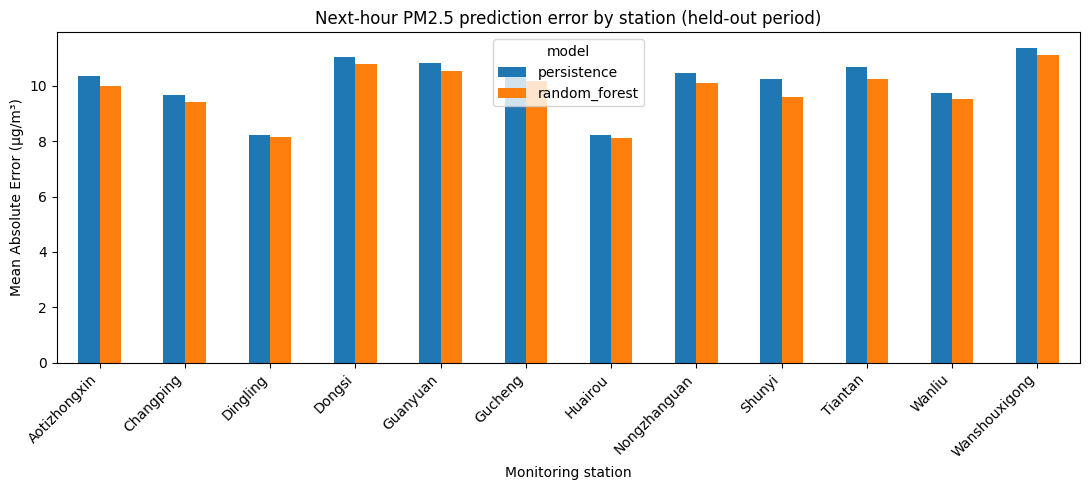

In [6]:
# Save a reproducible figure for the paper/poster
import matplotlib.pyplot as plt
fig, ax=plt.subplots(figsize=(11,5))
chart=station_eval.pivot(index='station',columns='model',values='MAE').sort_index()
chart.plot(kind='bar',ax=ax)
ax.set_ylabel('Mean Absolute Error (µg/m³)')
ax.set_xlabel('Monitoring station')
ax.set_title('Next-hour PM2.5 prediction error by station (held-out period)')
plt.xticks(rotation=45,ha='right');plt.tight_layout()
plt.savefig('station_mae_comparison.png',dpi=180)
plt.show()

## Interpretation and limitations
- The persistence baseline is essential: a complex model must be compared with a simple forecast.
- This is an **observational prediction** experiment, not a causal analysis of policies or station neighborhoods.
- Station-level error differences do not alone establish environmental injustice or unequal monitoring access.
- Current-hour covariates are valid only if known at the forecast issue time. All fitted preprocessing is trained on the training partition only.
- This starter uses a single chronological holdout. Extend with rolling temporal validation and a separate unseen-station experiment for your final project.
- Data credit: Chen, S. (2017). *Beijing Multi-Site Air Quality*. UCI Machine Learning Repository. https://doi.org/10.24432/C5RK5G (CC BY 4.0).